# EV energy dataset - paper-based feature engineering and EDA

This notebook does three simple things:
1. Loads `EV_Energy_Consumption_Dataset.csv`.
2. Creates the physics-guided features described by Equations 52-56 of the supplied paper.
3. Visualizes feature distributions and correlations.

No machine-learning model is trained in this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:.4f}')

# Locate the CSV whether Jupyter starts in the repository root or notebooks/.
cwd = Path.cwd().resolve()
candidates = [
    cwd / 'ev_energy_kaggle' / 'EV_Energy_Consumption_Dataset.csv',
    cwd / 'EV_Energy_Consumption_Dataset.csv',
    cwd.parent / 'EV_Energy_Consumption_Dataset.csv',
]
DATA_PATH = next((path for path in candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('EV_Energy_Consumption_Dataset.csv was not found.')
print('Dataset:', DATA_PATH)

Dataset: C:\Users\Yessine\Desktop\vehicle_ai_copilote\ev_energy_kaggle\EV_Energy_Consumption_Dataset.csv


## 1. Load and inspect the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

print(f'Rows: {len(df):,}')
print(f'Columns: {df.shape[1]}')
print(f'Unique vehicles: {df["Vehicle_ID"].nunique():,}')
print(f'Missing values: {int(df.isna().sum().sum()):,}')
print(f'Duplicate rows: {int(df.duplicated().sum()):,}')
display(df.head())
display(df.describe(include='all').T)

Rows: 5,000
Columns: 19
Unique vehicles: 989
Missing values: 0
Duplicate rows: 0


,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.5074,-2.7738,30.4151,378.0915,25.3148,2,1,1,6.8794,4,0.7418,42.1725,7.8293,31.1120,1822.9674,20.7575,12.0543
1,1435,2024-01-01 00:01:00,48.6123,-0.7970,97.3855,392.7184,18.2408,1,2,1,-3.0072,4,-3.4955,57.0184,4.4956,31.5044,2091.8319,0.6429,4.4887
2,1860,2024-01-01 00:02:00,108.7333,0.2538,84.9126,398.9935,44.4491,1,1,3,0.0296,1,9.2483,69.0289,5.1445,33.8380,1816.7025,40.8428,11.7014
3,1270,2024-01-01 00:03:00,38.5795,-2.1114,28.7779,358.1283,28.9802,1,2,2,8.2719,3,2.8684,86.6383,4.5183,33.2560,1283.1026,5.3052,7.3893
4,1106,2024-01-01 00:04:00,57.1724,1.4779,29.7402,310.8882,33.1846,2,1,1,2.7768,2,16.7502,27.1892,4.2634,33.5797,2160.3508,5.8259,6.7612


,count,mean,min,25%,50%,75%,max,std
Vehicle_ID,5000.0000,1505.7012,1000.0000,1253.0000,1510.0000,1761.0000,1999.0000,290.8369
Timestamp,5000,2024-01-02 17:39:30,2024-01-01 00:00:00,2024-01-01 20:49:45,2024-01-02 17:39:30,2024-01-03 14:29:15,2024-01-04 11:19:00,NaN
Speed_kmh,5000.0000,59.3130,0.0014,29.5154,58.6468,89.0300,119.9469,34.5176
Acceleration_ms2,5000.0000,-0.0199,-2.9997,-1.4902,-0.0433,1.4739,2.9980,1.7243
Battery_State_%,5000.0000,60.2145,20.0202,40.0883,60.4903,80.4099,99.9940,23.1283
Battery_Voltage_V,5000.0000,351.1183,300.0048,326.6134,351.5109,375.9681,399.9901,28.9684
Battery_Temperature_C,5000.0000,27.5101,10.0039,18.8847,27.5817,35.9202,44.9859,10.0154
Driving_Mode,5000.0000,2.0110,1.0000,1.0000,2.0000,3.0000,3.0000,0.8101
Road_Type,5000.0000,1.9992,1.0000,1.0000,2.0000,3.0000,3.0000,0.8085
Traffic_Condition,5000.0000,2.0108,1.0000,1.0000,2.0000,3.0000,3.0000,0.8122


## 2. Paper-based physics feature engineering

The paper describes total longitudinal demand as:


$$F_{total}=F_{drag}+F_{roll}+F_{slope}+F_{acc}$$

with aerodynamic drag, rolling resistance, road-slope load, acceleration load and a simplified wind term.

The CSV does not contain calibrated drag or rolling-resistance coefficients. Therefore `rho=1.225 kg/m³`, `CdA=0.65 m²`, `Crr=0.012`, and `g=9.81 m/s²` are clearly labeled assumptions.

In [3]:
# Explicit assumptions used because vehicle-specific coefficients are absent.
AIR_DENSITY_KG_M3 = 1.225
CDA_M2 = 0.65
ROLLING_RESISTANCE_COEFFICIENT = 0.012
GRAVITY_M_S2 = 9.81

df_fe = df.copy()
speed_m_s = df_fe['Speed_kmh'].clip(lower=0) / 3.6
acceleration_m_s2 = df_fe['Acceleration_ms2']
vehicle_mass_kg = df_fe['Vehicle_Weight_kg']
slope_ratio = df_fe['Slope_%'] / 100.0
wind_speed_m_s = df_fe['Wind_Speed_ms'].clip(lower=0)

# Speed-squared aerodynamic indicator.
df_fe['speed_squared_ms2'] = speed_m_s ** 2

# F_roll = Crr * m * g
df_fe['rolling_force_assumed_N'] = (
    ROLLING_RESISTANCE_COEFFICIENT * vehicle_mass_kg * GRAVITY_M_S2
)

# F_slope = m * g * sin(theta), where theta = atan(slope / 100).
df_fe['slope_force_proxy_N'] = (
    vehicle_mass_kg * GRAVITY_M_S2 * np.sin(np.arctan(slope_ratio))
)

# Acceleration-dependent inertial force, F_acc = m * a.
df_fe['inertial_force_proxy_N'] = vehicle_mass_kg * acceleration_m_s2

# Simplified paper wind expression. This assumes direct headwind alignment.
df_fe['wind_headwind_upper_proxy_ms2'] = (speed_m_s + wind_speed_m_s) ** 2

# F_drag = 0.5 * rho * CdA * v^2.
df_fe['aero_force_assumed_N'] = (
    0.5 * AIR_DENSITY_KG_M3 * CDA_M2 * speed_m_s ** 2
)

PHYSICS_FEATURES = [
    'speed_squared_ms2',
    'rolling_force_assumed_N',
    'slope_force_proxy_N',
    'inertial_force_proxy_N',
    'wind_headwind_upper_proxy_ms2',
    'aero_force_assumed_N',
]
display(df_fe[PHYSICS_FEATURES].head())
display(df_fe[PHYSICS_FEATURES].describe().T)

,speed_squared_ms2,rolling_force_assumed_N,slope_force_proxy_N,inertial_force_proxy_N,wind_headwind_upper_proxy_ms2,aero_force_assumed_N
0,959.4053,214.5997,1227.3716,-5056.5754,1505.7133,381.9632
1,182.3424,246.2505,-616.8273,-1667.1529,323.9638,72.5951
2,912.2635,213.8622,5.2725,461.0788,1249.4944,363.1949
3,114.8439,151.0468,1037.6650,-2709.1368,232.0993,45.7222
4,252.2136,254.3165,588.2647,3192.7454,405.8065,100.4125


,count,mean,std,min,25%,50%,75%,max
speed_squared_ms2,5000.0000,363.3683,329.7921,0.0000,67.2191,265.3894,611.6004,1110.1284
rolling_force_assumed_N,5000.0000,218.3376,43.9902,141.3770,180.2785,219.5486,256.7557,294.2417
slope_force_proxy_N,5000.0000,449.7585,809.7818,-1209.5279,-219.2052,430.6310,1088.6865,2428.4781
inertial_force_proxy_N,5000.0000,-29.3738,3253.6949,-7393.2867,-2678.5899,-78.7981,2625.3485,7444.8168
wind_headwind_upper_proxy_ms2,5000.0000,687.3121,525.2668,1.1078,246.5106,561.4200,1038.5744,2297.3487
aero_force_assumed_N,5000.0000,144.6660,131.2985,0.0000,26.7616,105.6582,243.4934,441.9699


## 3. Target and original-feature distributions

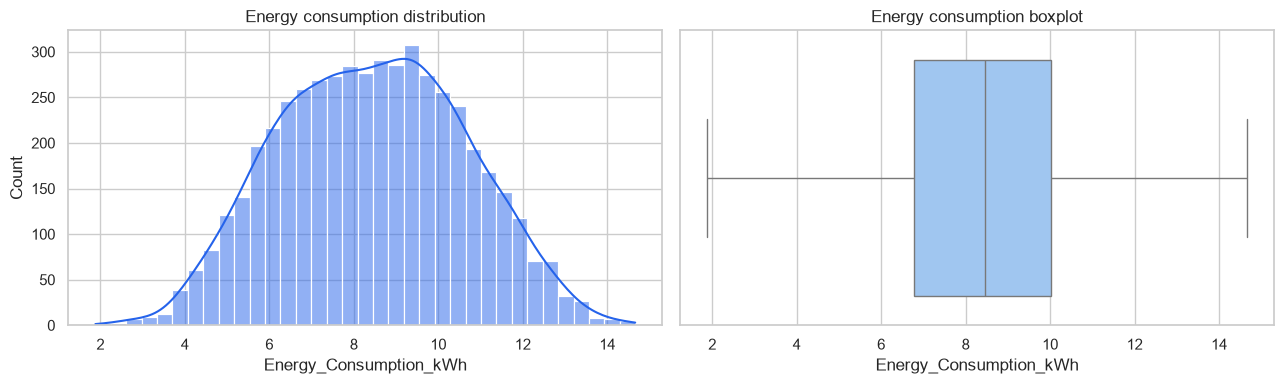

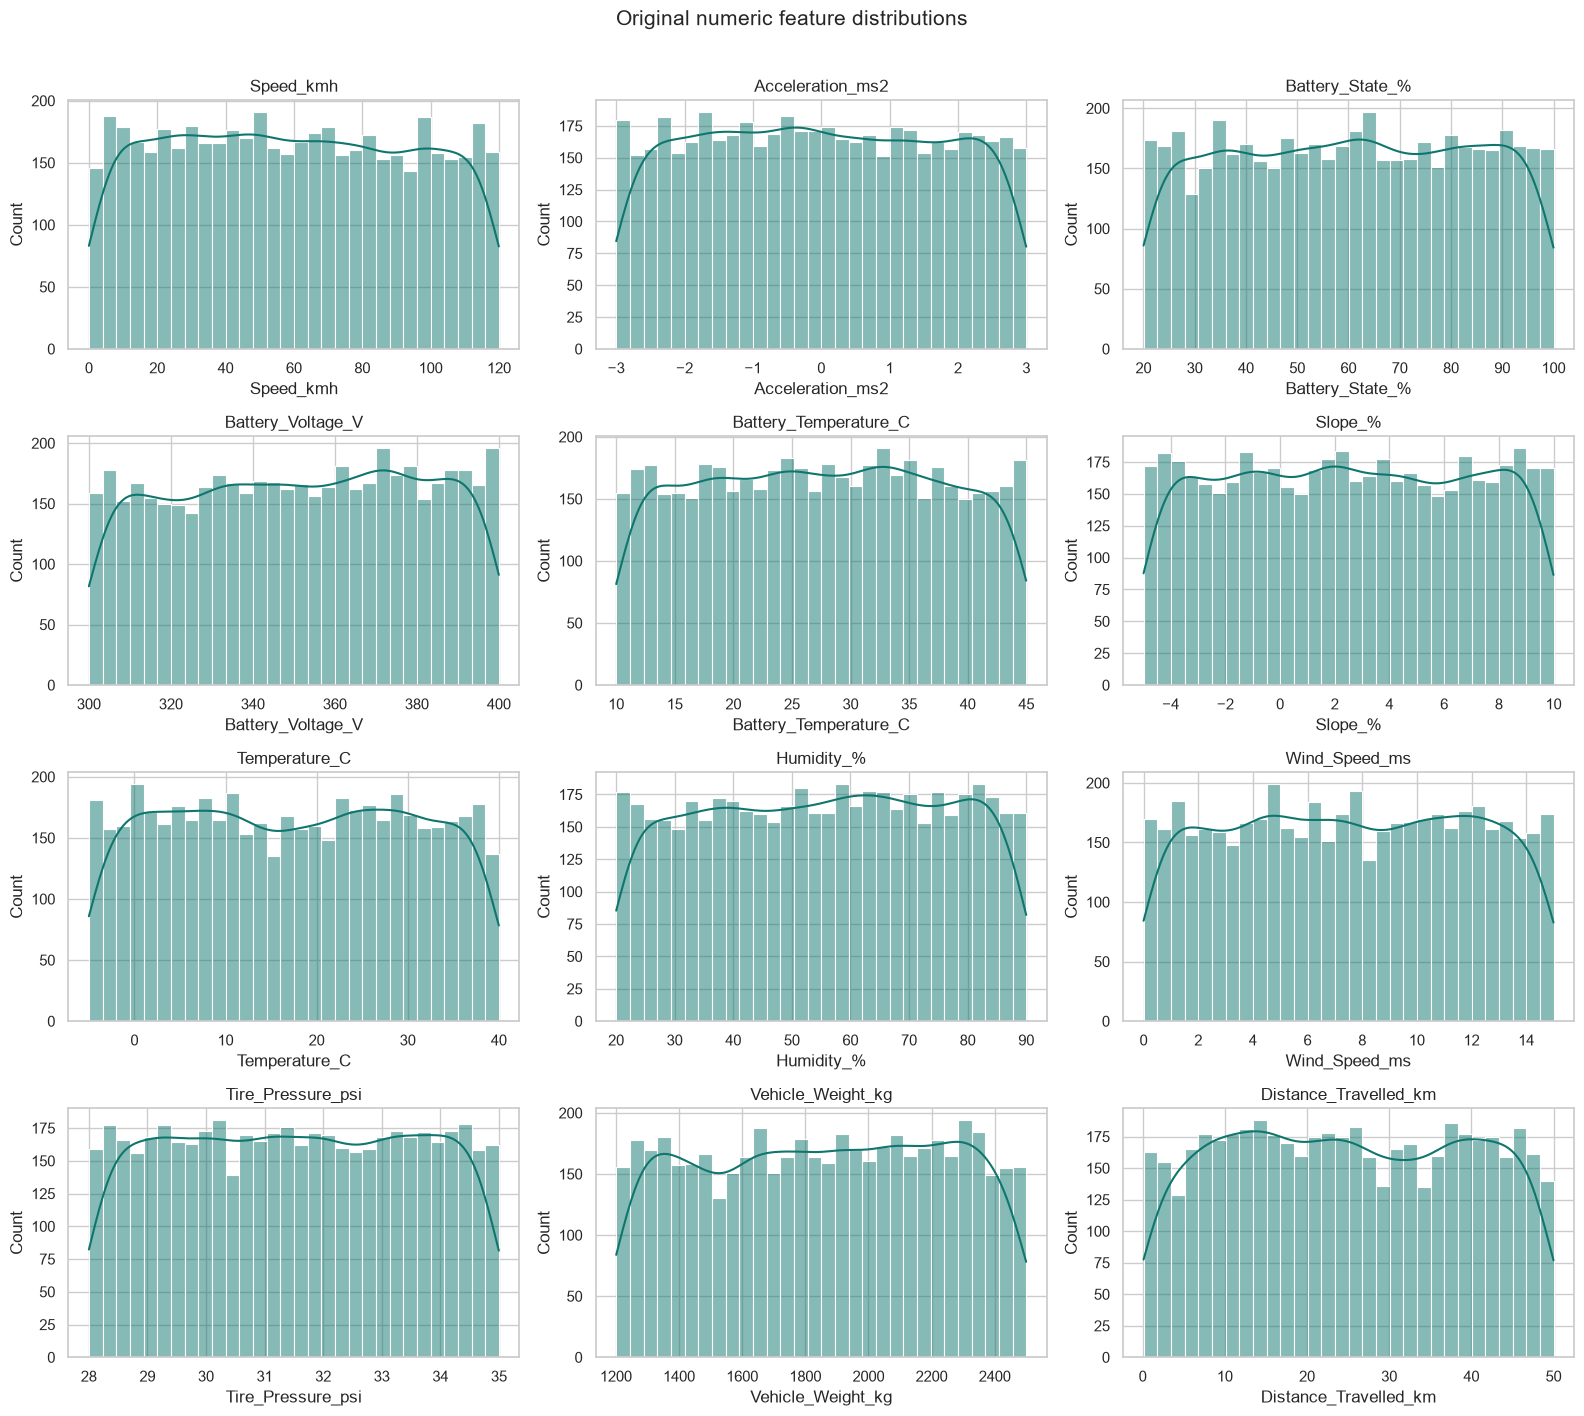

In [4]:
TARGET = 'Energy_Consumption_kWh'
ORIGINAL_NUMERIC_FEATURES = [
    'Speed_kmh', 'Acceleration_ms2', 'Battery_State_%',
    'Battery_Voltage_V', 'Battery_Temperature_C', 'Slope_%',
    'Temperature_C', 'Humidity_%', 'Wind_Speed_ms',
    'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km',
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_fe[TARGET], bins=35, kde=True, ax=axes[0], color='#2563eb')
axes[0].set_title('Energy consumption distribution')
sns.boxplot(x=df_fe[TARGET], ax=axes[1], color='#93c5fd')
axes[1].set_title('Energy consumption boxplot')
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, feature in zip(axes.flat, ORIGINAL_NUMERIC_FEATURES):
    sns.histplot(df_fe[feature], bins=30, kde=True, ax=ax, color='#0f766e')
    ax.set_title(feature)
fig.suptitle('Original numeric feature distributions', fontsize=15, y=1.01)
fig.tight_layout(); plt.show()

## 4. Physics-feature distributions

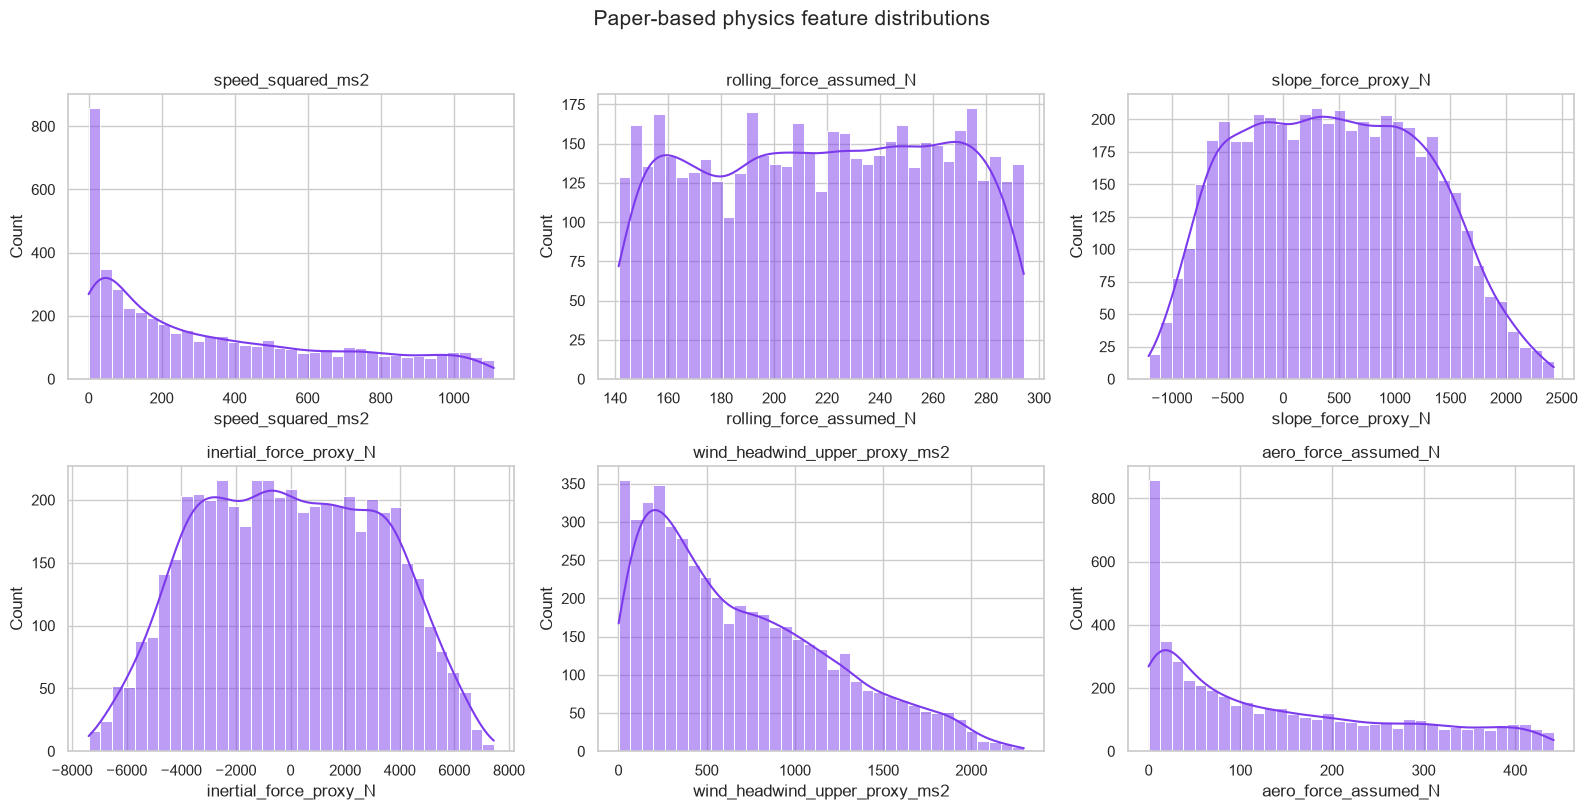

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flat, PHYSICS_FEATURES):
    sns.histplot(df_fe[feature], bins=35, kde=True, ax=ax, color='#7c3aed')
    ax.set_title(feature)
fig.suptitle('Paper-based physics feature distributions', fontsize=15, y=1.01)
fig.tight_layout(); plt.show()

## 5. Categorical distributions
The integer codes are category labels, not continuous physical measurements.

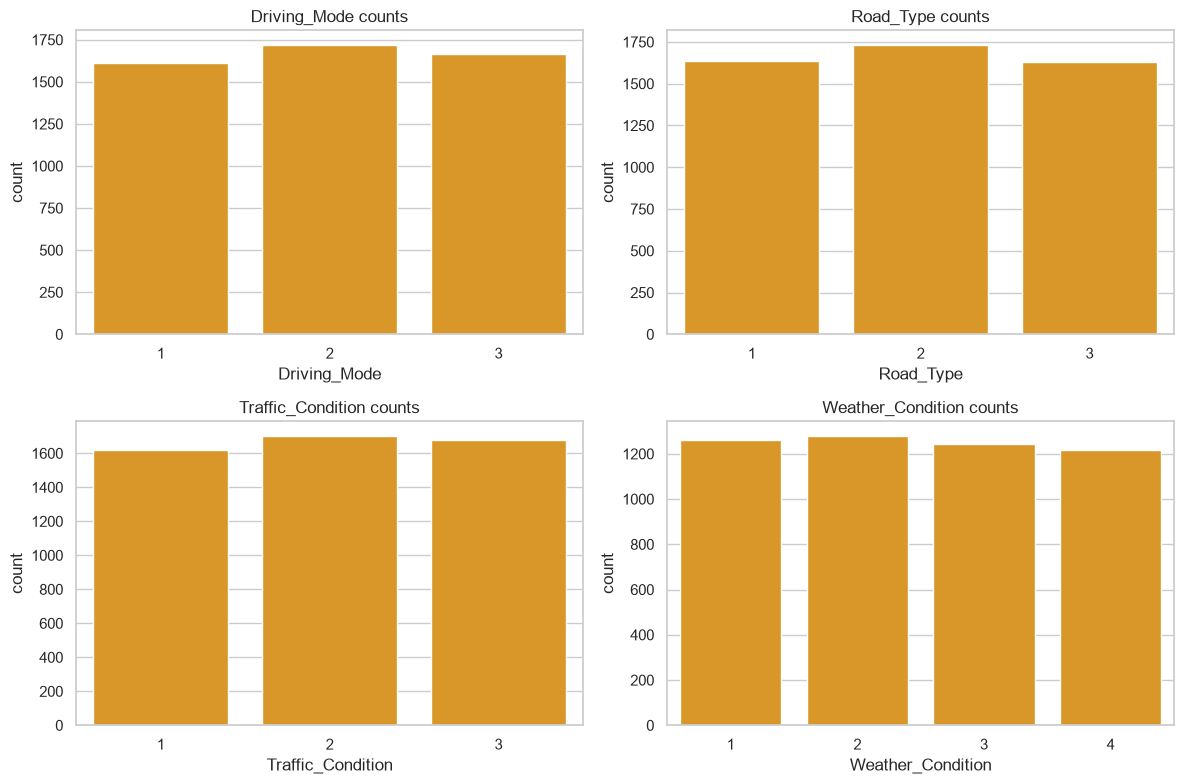

In [6]:
CATEGORICAL_FEATURES = [
    'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition'
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, CATEGORICAL_FEATURES):
    sns.countplot(data=df_fe, x=feature, ax=ax, color='#f59e0b')
    ax.set_title(f'{feature} counts')
fig.tight_layout(); plt.show()

## 6. Correlation analysis
Categorical codes are excluded. Pearson correlation measures linear association; Spearman measures monotonic association.

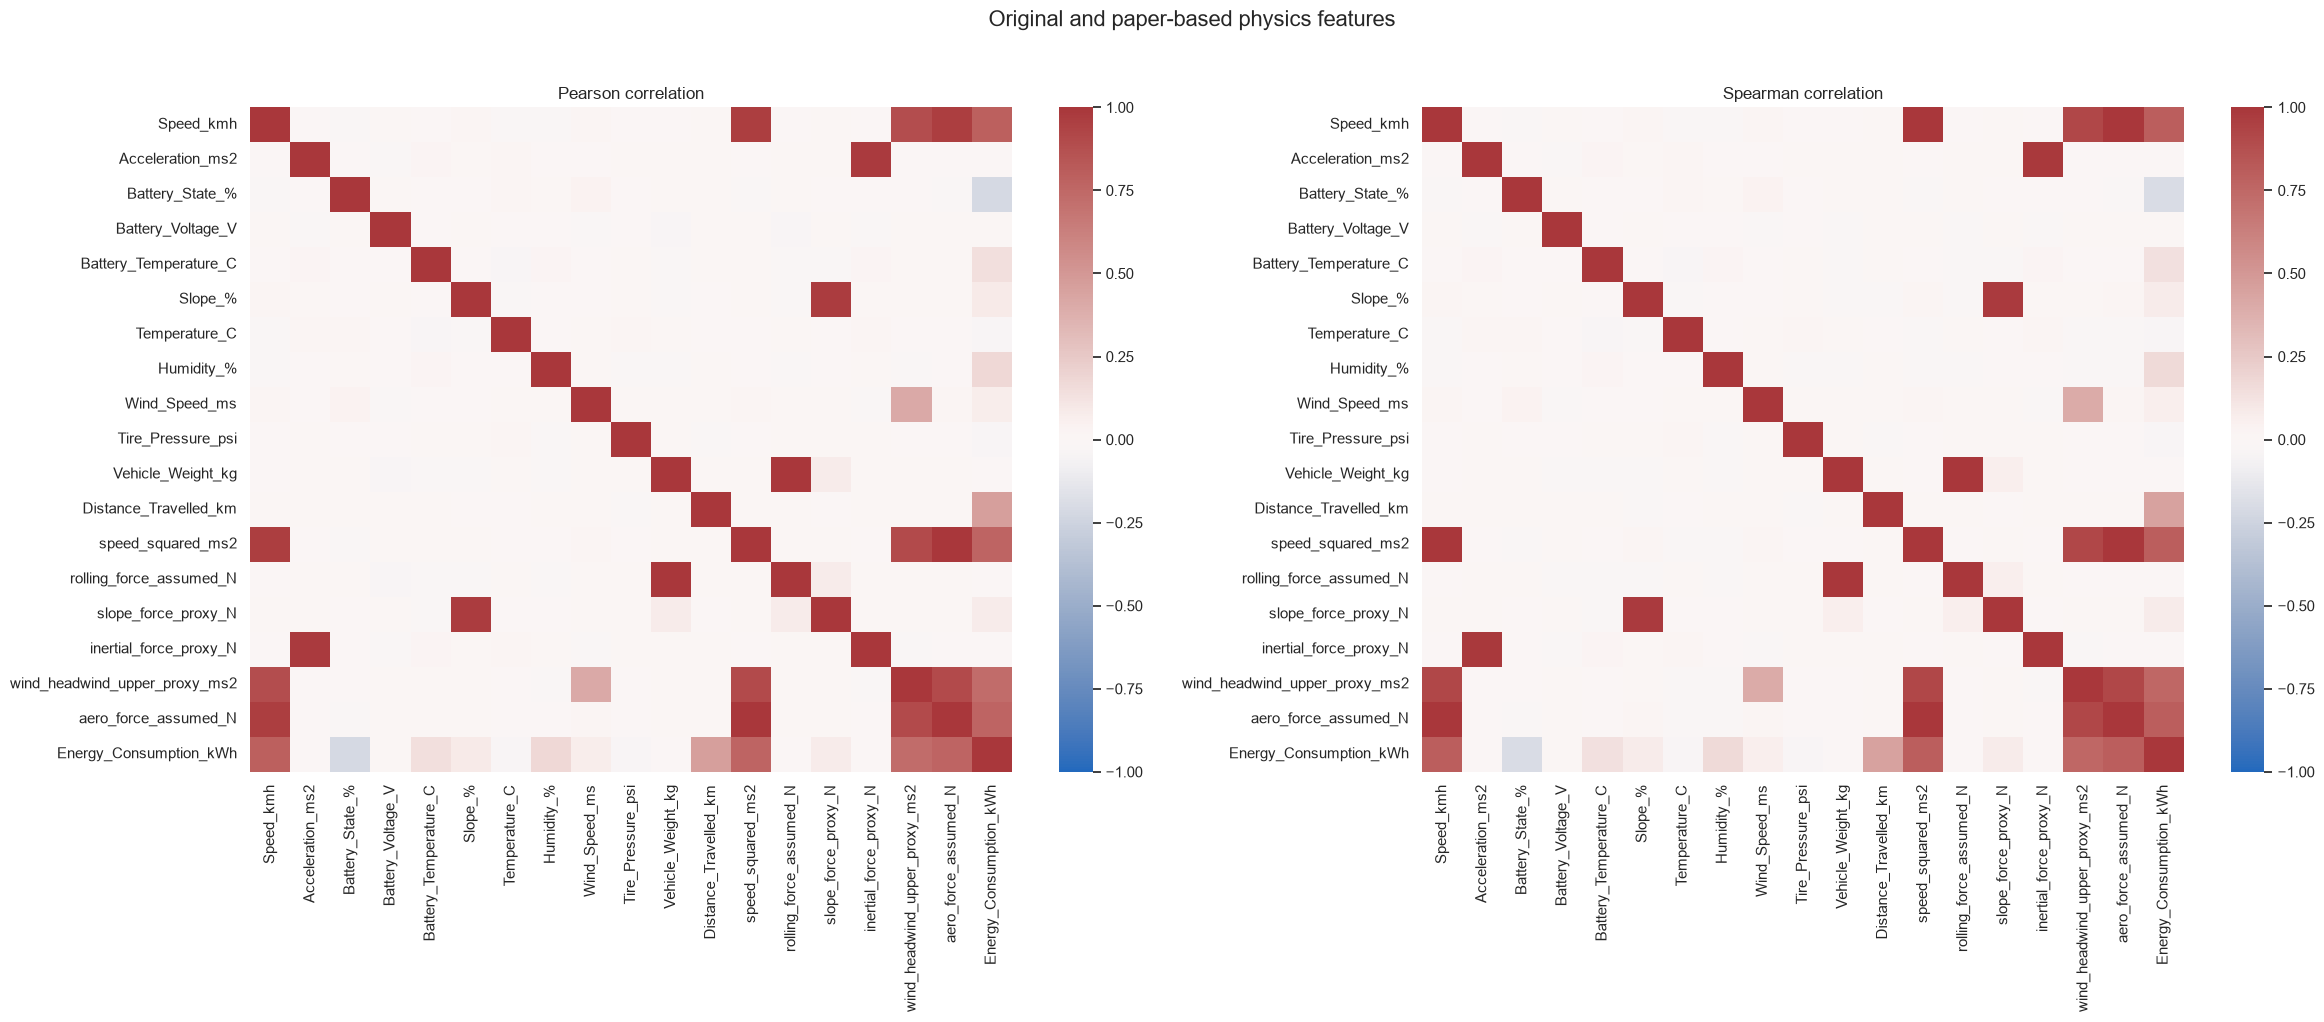

In [7]:
CORRELATION_FEATURES = ORIGINAL_NUMERIC_FEATURES + PHYSICS_FEATURES + [TARGET]
pearson_corr = df_fe[CORRELATION_FEATURES].corr(method='pearson')
spearman_corr = df_fe[CORRELATION_FEATURES].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
sns.heatmap(pearson_corr, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[0],)
axes[0].set_title('Pearson correlation')
sns.heatmap(spearman_corr, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman correlation')
fig.suptitle('Original and paper-based physics features', fontsize=16, y=1.02)
fig.tight_layout(); plt.show()

## 7. Correlation with energy consumption
These values describe association only and do not establish causation or feature importance.

,Pearson,Spearman
Battery_State_%,-0.2138,-0.2017
Tire_Pressure_psi,-0.0363,-0.0371
Temperature_C,-0.0337,-0.0315
inertial_force_proxy_N,-0.0072,-0.0111
Acceleration_ms2,-0.0065,-0.0121
rolling_force_assumed_N,-0.0022,-0.0019
Vehicle_Weight_kg,-0.0022,-0.0019
Battery_Voltage_V,0.0101,0.0122
Wind_Speed_ms,0.0734,0.0686
slope_force_proxy_N,0.0816,0.0789


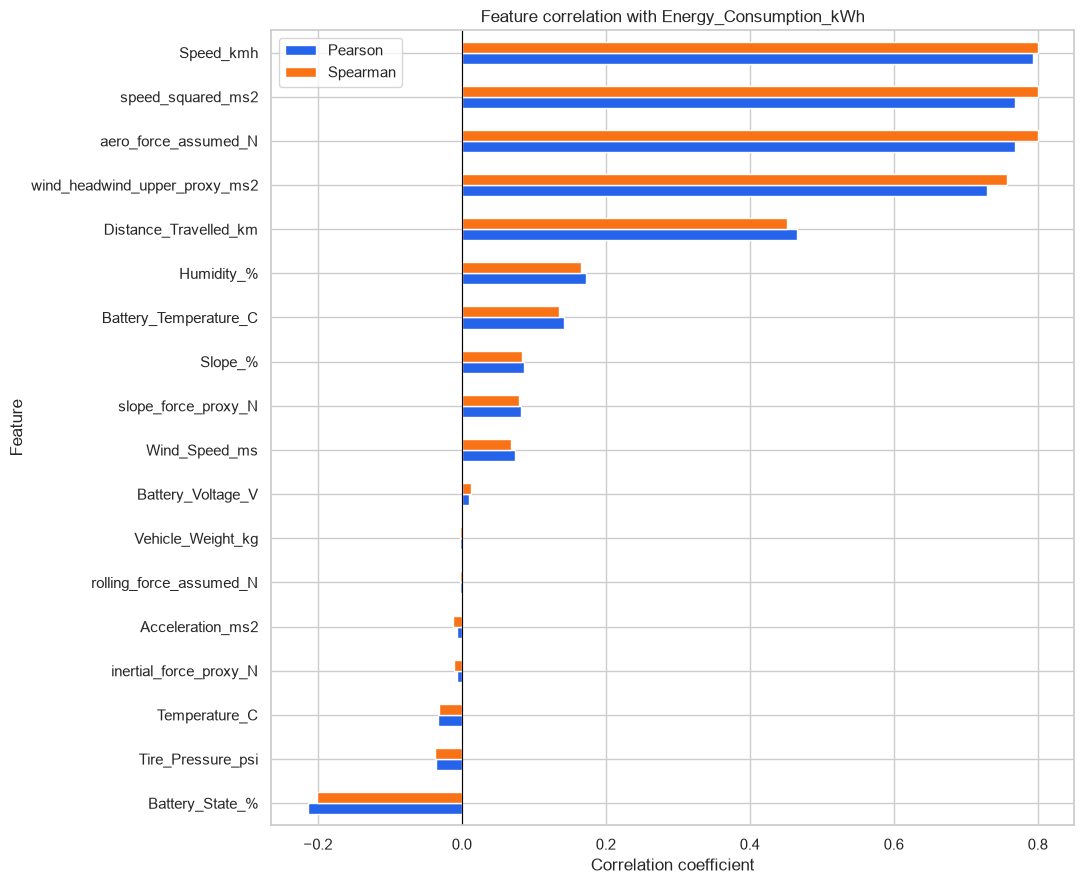

In [8]:
target_correlations = pd.DataFrame({
    'Pearson': pearson_corr[TARGET].drop(TARGET),
    'Spearman': spearman_corr[TARGET].drop(TARGET),
}).sort_values('Pearson')
display(target_correlations)

target_correlations.plot.barh(figsize=(11, 9), color=['#2563eb', '#f97316'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Feature correlation with Energy_Consumption_kWh')
plt.xlabel('Correlation coefficient')
plt.ylabel('Feature')
plt.tight_layout(); plt.show()

## 8. Base features versus their derived physics features

This section compares how strongly each original feature and its engineered counterpart relate to `Energy_Consumption_kWh`. Pearson measures linear association, while Spearman measures monotonic association.

In [9]:
BASE_DERIVED_PAIRS = {
    'Speed → Speed²': ('Speed_kmh', 'speed_squared_ms2'),
    'Speed → Aero force': ('Speed_kmh', 'aero_force_assumed_N'),
    'Wind speed → Headwind proxy': ('Wind_Speed_ms', 'wind_headwind_upper_proxy_ms2'),
    'Vehicle weight → Rolling force': ('Vehicle_Weight_kg', 'rolling_force_assumed_N'),
    'Road slope → Slope force': ('Slope_%', 'slope_force_proxy_N'),
    'Acceleration → Inertial force': ('Acceleration_ms2', 'inertial_force_proxy_N'),
}

target_comparisons = []
for relationship, (base_feature, derived_feature) in BASE_DERIVED_PAIRS.items():
    target_comparisons.append({
        'relationship': relationship,
        'base_feature': base_feature,
        'derived_feature': derived_feature,
        'base_pearson': df_fe[base_feature].corr(df_fe[TARGET], method='pearson'),
        'derived_pearson': df_fe[derived_feature].corr(df_fe[TARGET], method='pearson'),
        'base_spearman': df_fe[base_feature].corr(df_fe[TARGET], method='spearman'),
        'derived_spearman': df_fe[derived_feature].corr(df_fe[TARGET], method='spearman'),
    })

target_comparison_df = pd.DataFrame(target_comparisons).set_index('relationship')
display(target_comparison_df.round(4))

,base_feature,derived_feature,base_pearson,derived_pearson,base_spearman,derived_spearman
relationship,,,,,,
Speed → Speed²,Speed_kmh,speed_squared_ms2,0.7928,0.7689,0.7997,0.7997
Speed → Aero force,Speed_kmh,aero_force_assumed_N,0.7928,0.7689,0.7997,0.7997
Wind speed → Headwind proxy,Wind_Speed_ms,wind_headwind_upper_proxy_ms2,0.0734,0.7294,0.0686,0.7569
Vehicle weight → Rolling force,Vehicle_Weight_kg,rolling_force_assumed_N,-0.0022,-0.0022,-0.0019,-0.0019
Road slope → Slope force,Slope_%,slope_force_proxy_N,0.0867,0.0816,0.0832,0.0789
Acceleration → Inertial force,Acceleration_ms2,inertial_force_proxy_N,-0.0065,-0.0072,-0.0121,-0.0111


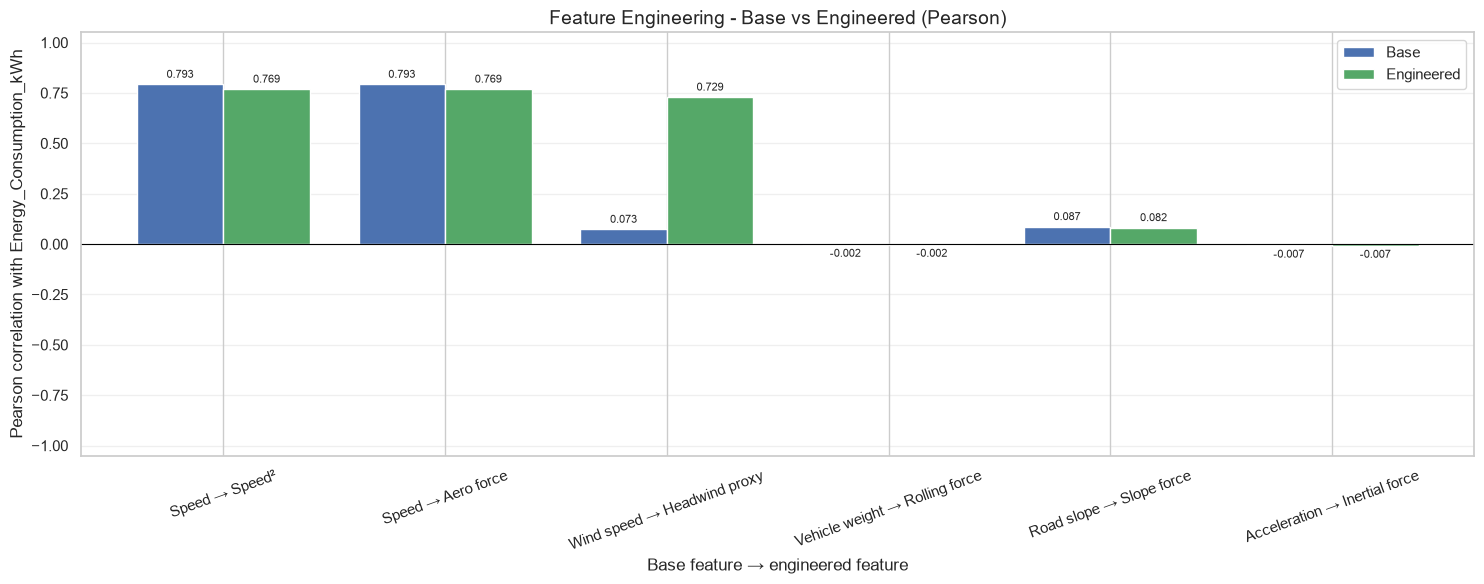

In [10]:
pearson_plot = target_comparison_df[['base_pearson', 'derived_pearson']].copy()
pearson_plot.columns = ['Base', 'Engineered']

ax = pearson_plot.plot.bar(
    figsize=(15, 6), color=['#4c72b0', '#55a868'], width=0.78
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Feature Engineering - Base vs Engineered (Pearson)', fontsize=14)
ax.set_ylabel('Pearson correlation with Energy_Consumption_kWh')
ax.set_xlabel('Base feature → engineered feature')
ax.set_ylim(-1.05, 1.05)
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8)
plt.tight_layout(); plt.show()

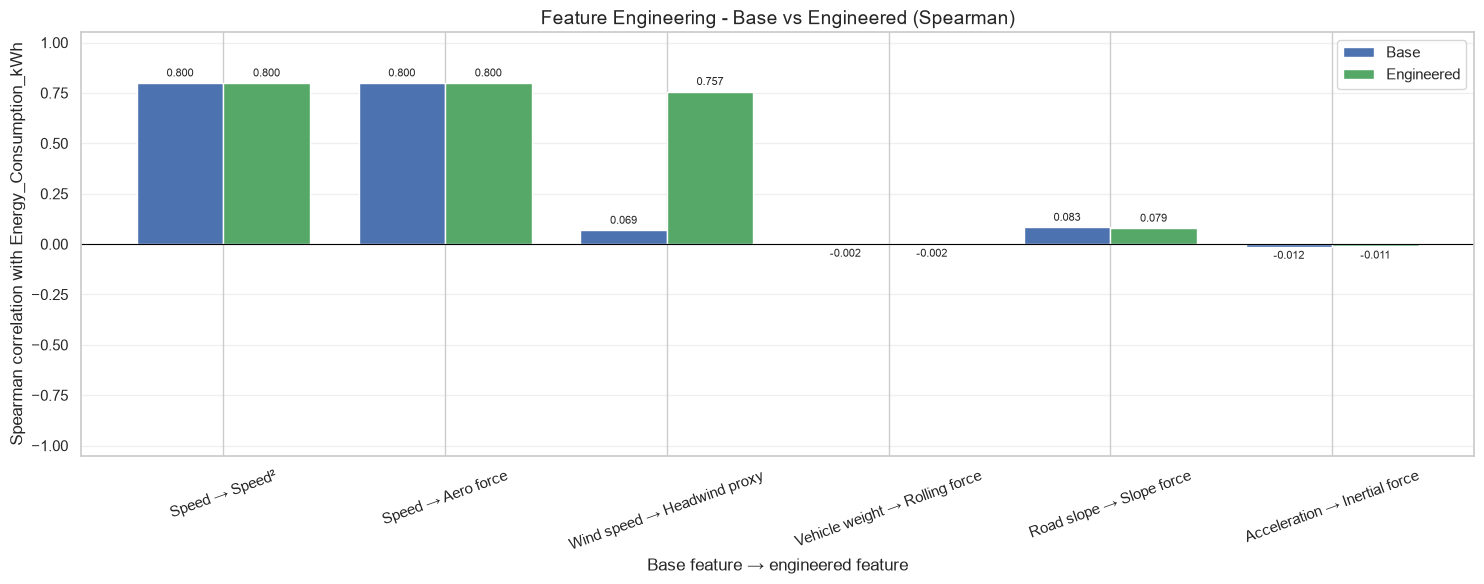

In [11]:
spearman_plot = target_comparison_df[['base_spearman', 'derived_spearman']].copy()
spearman_plot.columns = ['Base', 'Engineered']

ax = spearman_plot.plot.bar(
    figsize=(15, 6), color=['#4c72b0', '#55a868'], width=0.78
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Feature Engineering - Base vs Engineered (Spearman)', fontsize=14)
ax.set_ylabel('Spearman correlation with Energy_Consumption_kWh')
ax.set_xlabel('Base feature → engineered feature')
ax.set_ylim(-1.05, 1.05)
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8)
plt.tight_layout(); plt.show()

# Delete categorical features and slope feature

In [12]:
df_fe.columns

Index(['Vehicle_ID', 'Timestamp', 'Speed_kmh', 'Acceleration_ms2',
       'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C',
       'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Slope_%',
       'Weather_Condition', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms',
       'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km',
       'Energy_Consumption_kWh', 'speed_squared_ms2',
       'rolling_force_assumed_N', 'slope_force_proxy_N',
       'inertial_force_proxy_N', 'wind_headwind_upper_proxy_ms2',
       'aero_force_assumed_N'],
      dtype='str')

In [13]:
df_fs = df_fe.copy()
df_fs.drop(columns=['Slope_%','Vehicle_ID','Timestamp','Driving_Mode', 'Road_Type', 'Traffic_Condition','Weather_Condition'], inplace=True)

# 9. Train models after correlation-based feature selection

The rows are treated as independent observations, not as a time series. A shuffled test set is separated **before** feature selection. High-correlation pairs are detected using training data only, candidates are compared with shuffled K-fold cross-validation, and the untouched test set is used once for the winner.

In [14]:
from itertools import product

from sklearn.base import clone
from sklearn.ensemble import (
    ExtraTreesRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# Rows are independent: use a reproducible shuffled 80/20 holdout split.
model_data = df_fs.reset_index(drop=True)
X_all = model_data.drop(columns=[TARGET])
y_all = model_data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, shuffle=True, random_state=42
)

print(f'Training rows: {len(X_train):,}')
print(f'Test rows: {len(X_test):,}')
print(f'Candidate numeric features: {X_train.shape[1]}')

Training rows: 4,000
Test rows: 1,000
Candidate numeric features: 17


In [15]:
# Detect pairs that are strongly associated by either correlation method.
CORRELATION_THRESHOLD = 0.90
pearson_train = X_train.corr(method='pearson').abs()
spearman_train = X_train.corr(method='spearman').abs()

high_correlation_pairs = []
columns = X_train.columns.tolist()
for left_index, left in enumerate(columns):
    for right in columns[left_index + 1:]:
        pearson_value = pearson_train.loc[left, right]
        spearman_value = spearman_train.loc[left, right]
        if max(pearson_value, spearman_value) >= CORRELATION_THRESHOLD:
            high_correlation_pairs.append({
                'feature_1': left,
                'feature_2': right,
                'pearson_abs': pearson_value,
                'spearman_abs': spearman_value,
            })

high_correlation_df = pd.DataFrame(high_correlation_pairs)
display(high_correlation_df.round(4))

# Merge overlapping pairs into correlated groups. Keeping one representative
# per group tests all meaningful combinations without redundant feature sets.
adjacency = {feature: set() for feature in columns}
for pair in high_correlation_pairs:
    adjacency[pair['feature_1']].add(pair['feature_2'])
    adjacency[pair['feature_2']].add(pair['feature_1'])

correlated_groups = []
visited = set()
for feature in columns:
    if feature in visited or not adjacency[feature]:
        continue
    stack, component = [feature], []
    while stack:
        current = stack.pop()
        if current in visited:
            continue
        visited.add(current)
        component.append(current)
        stack.extend(adjacency[current] - visited)
    correlated_groups.append(sorted(component))

grouped_features = {feature for group in correlated_groups for feature in group}
fixed_features = [feature for feature in columns if feature not in grouped_features]
feature_candidates = []
representative_sets = product(*correlated_groups) if correlated_groups else [()]
for representatives in representative_sets:
    selected = fixed_features + list(representatives)
    feature_candidates.append({
        'candidate': ' | '.join(representatives) if representatives else 'all_features',
        'features': selected,
    })

print('Correlated groups:')
for group in correlated_groups:
    print(' -', group)
print(f'Feature combinations to evaluate: {len(feature_candidates)}')

,feature_1,feature_2,pearson_abs,spearman_abs
0,Speed_kmh,speed_squared_ms2,0.9682,1.0000
1,Speed_kmh,wind_headwind_upper_proxy_ms2,0.8888,0.9174
2,Speed_kmh,aero_force_assumed_N,0.9682,1.0000
3,Acceleration_ms2,inertial_force_proxy_N,0.9801,0.9853
4,Vehicle_Weight_kg,rolling_force_assumed_N,1.0000,1.0000
5,speed_squared_ms2,wind_headwind_upper_proxy_ms2,0.9005,0.9174
6,speed_squared_ms2,aero_force_assumed_N,1.0000,1.0000
7,wind_headwind_upper_proxy_ms2,aero_force_assumed_N,0.9005,0.9174


Correlated groups:
 - ['Speed_kmh', 'aero_force_assumed_N', 'speed_squared_ms2', 'wind_headwind_upper_proxy_ms2']
 - ['Acceleration_ms2', 'inertial_force_proxy_N']
 - ['Vehicle_Weight_kg', 'rolling_force_assumed_N']
Feature combinations to evaluate: 16


,candidate,model,feature_count,cv_mae,cv_rmse,cv_r2
0,Speed_kmh | inertial_force_proxy_N | rolling_f...,LinearRegression,12,0.4183,0.5226,0.9424
1,Speed_kmh | inertial_force_proxy_N | Vehicle_W...,LinearRegression,12,0.4183,0.5226,0.9424
2,Speed_kmh | inertial_force_proxy_N | rolling_f...,Ridge,12,0.4183,0.5226,0.9424
3,Speed_kmh | inertial_force_proxy_N | Vehicle_W...,Ridge,12,0.4183,0.5226,0.9424
4,Speed_kmh | Acceleration_ms2 | Vehicle_Weight_kg,LinearRegression,12,0.4184,0.5227,0.9424
5,Speed_kmh | Acceleration_ms2 | rolling_force_a...,LinearRegression,12,0.4184,0.5227,0.9424
6,Speed_kmh | Acceleration_ms2 | rolling_force_a...,Ridge,12,0.4184,0.5227,0.9424
7,Speed_kmh | Acceleration_ms2 | Vehicle_Weight_kg,Ridge,12,0.4184,0.5227,0.9424
8,aero_force_assumed_N | Acceleration_ms2 | Vehi...,GradientBoosting,12,0.4527,0.5707,0.9313
9,aero_force_assumed_N | Acceleration_ms2 | roll...,GradientBoosting,12,0.4527,0.5707,0.9313


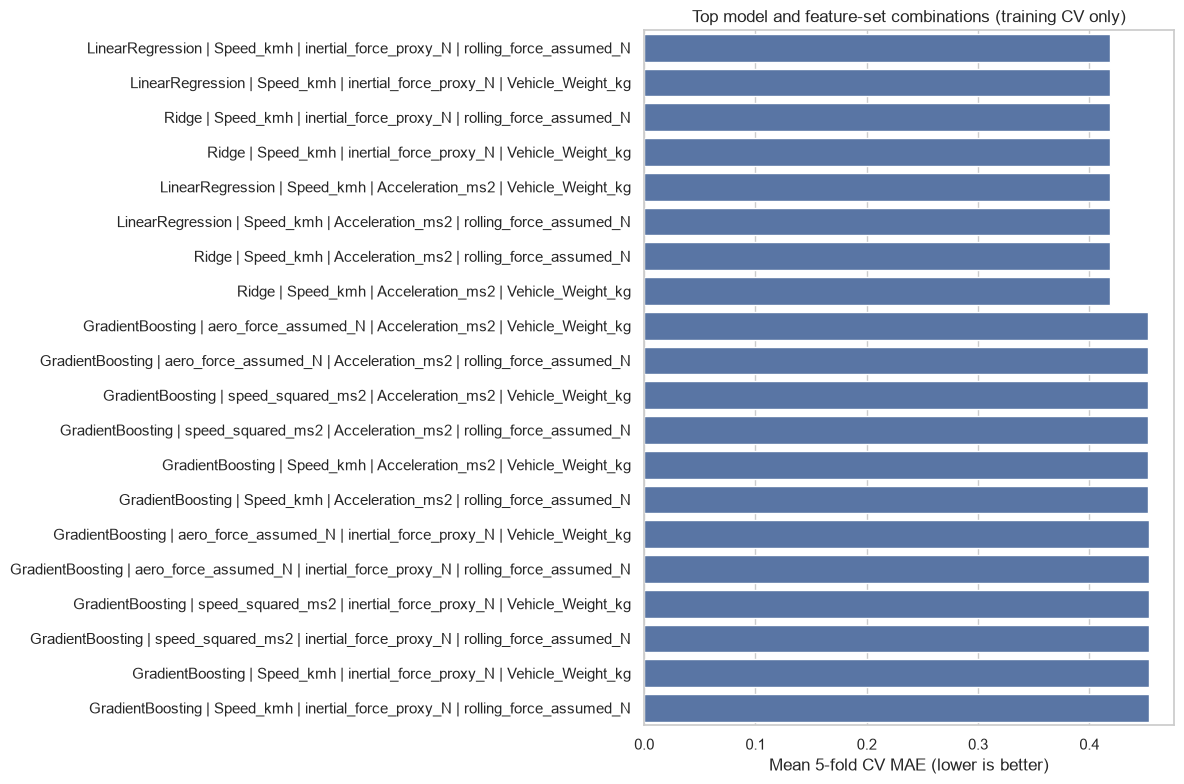

In [16]:
MODELS = {
    'LinearRegression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'RandomForest': RandomForestRegressor(
        n_estimators=120, random_state=42, n_jobs=-1
    ),
    'ExtraTrees': ExtraTreesRegressor(
        n_estimators=120, random_state=42, n_jobs=-1
    ),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        objective='reg:squarederror', eval_metric='mae',
        random_state=42, n_jobs=-1,
    ),
}

kfold_cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}
validation_results = []

for candidate_info in feature_candidates:
    selected_features = candidate_info['features']
    for model_name, model in MODELS.items():
        scores = cross_validate(
            model, X_train[selected_features], y_train,
            cv=kfold_cv, scoring=scoring, n_jobs=1, error_score='raise',
        )
        validation_results.append({
            'candidate': candidate_info['candidate'],
            'model': model_name,
            'feature_count': len(selected_features),
            'features': selected_features,
            'cv_mae': -scores['test_mae'].mean(),
            'cv_rmse': -scores['test_rmse'].mean(),
            'cv_r2': scores['test_r2'].mean(),
        })

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values(['cv_mae', 'cv_rmse'], ascending=True)
    .reset_index(drop=True)
)
display(validation_results_df.drop(columns='features').head(20).round(4))

top_results = validation_results_df.head(20).copy()
top_results['label'] = top_results['model'] + ' | ' + top_results['candidate']
plt.figure(figsize=(12, 8))
sns.barplot(data=top_results, y='label', x='cv_mae', color='#4c72b0')
plt.title('Top model and feature-set combinations (training CV only)')
plt.xlabel('Mean 5-fold CV MAE (lower is better)')
plt.ylabel('')
plt.tight_layout(); plt.show()

## 10. Fit the winner and evaluate the untouched test set

Only the best cross-validation result is fitted on all training rows and evaluated on the untouched shuffled 20% test set.

,value
model,LinearRegression
selected_candidate,Speed_kmh | inertial_force_proxy_N | rolling_f...
feature_count,12
test_mae_kwh,0.4096
test_rmse_kwh,0.5142
test_r2,0.9455


Selected features:
 - Battery_State_%
 - Battery_Voltage_V
 - Battery_Temperature_C
 - Temperature_C
 - Humidity_%
 - Wind_Speed_ms
 - Tire_Pressure_psi
 - Distance_Travelled_km
 - slope_force_proxy_N
 - Speed_kmh
 - inertial_force_proxy_N
 - rolling_force_assumed_N


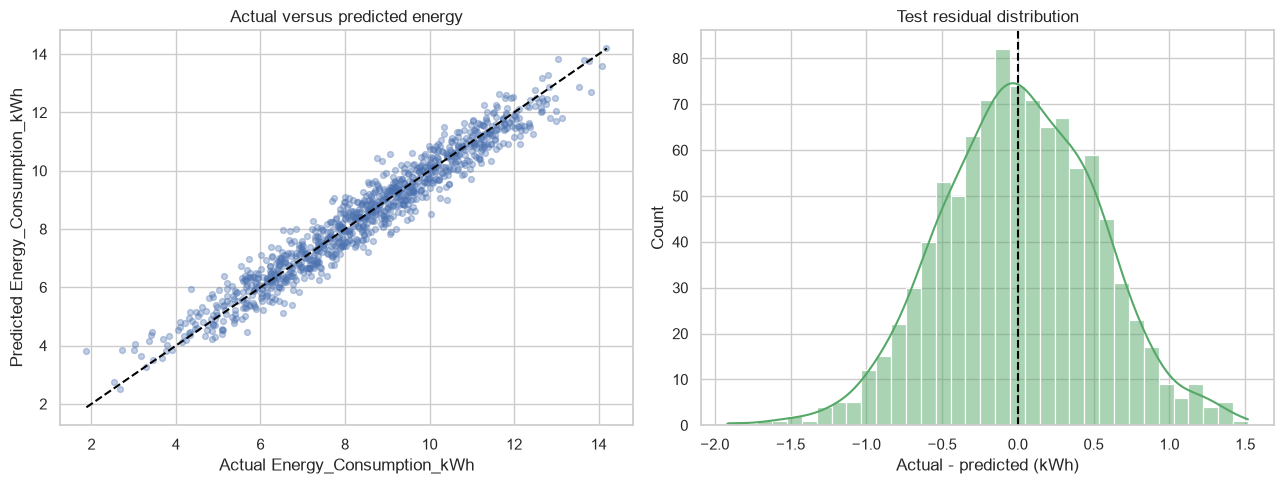

In [17]:
best_result = validation_results_df.iloc[0]
best_model_name = best_result['model']
best_features = best_result['features']
best_model = clone(MODELS[best_model_name])

best_model.fit(X_train[best_features], y_train)
test_predictions = best_model.predict(X_test[best_features])

test_metrics = pd.Series({
    'model': best_model_name,
    'selected_candidate': best_result['candidate'],
    'feature_count': len(best_features),
    'test_mae_kwh': mean_absolute_error(y_test, test_predictions),
    'test_rmse_kwh': mean_squared_error(y_test, test_predictions) ** 0.5,
    'test_r2': r2_score(y_test, test_predictions),
})
display(test_metrics.to_frame('value'))
print('Selected features:')
for feature in best_features:
    print(' -', feature)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, test_predictions, alpha=0.35, s=18, color='#4c72b0')
lower = min(y_test.min(), test_predictions.min())
upper = max(y_test.max(), test_predictions.max())
axes[0].plot([lower, upper], [lower, upper], '--', color='black')
axes[0].set_title('Actual versus predicted energy')
axes[0].set_xlabel('Actual Energy_Consumption_kWh')
axes[0].set_ylabel('Predicted Energy_Consumption_kWh')

residuals = y_test.to_numpy() - test_predictions
sns.histplot(residuals, bins=35, kde=True, ax=axes[1], color='#55a868')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Test residual distribution')
axes[1].set_xlabel('Actual - predicted (kWh)')
fig.tight_layout(); plt.show()

## 11. Save the winning model

Save the fitted model, its ordered input features, metrics, and the complete validation leaderboard under `notebooks/output/`.

In [18]:
import json
import joblib

# Locate notebooks/ whether Jupyter starts in the repository root,
# ev_energy_kaggle/, or ev_energy_kaggle/notebooks/.
if cwd.name == 'notebooks':
    NOTEBOOK_DIR = cwd
elif (cwd / 'ev_energy_kaggle' / 'notebooks').is_dir():
    NOTEBOOK_DIR = cwd / 'ev_energy_kaggle' / 'notebooks'
elif (cwd / 'notebooks').is_dir():
    NOTEBOOK_DIR = cwd / 'notebooks'
else:
    raise FileNotFoundError('Could not locate the ev_energy_kaggle/notebooks directory.')

OUTPUT_DIR = NOTEBOOK_DIR / 'output'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / 'best_energy_model.joblib'
METADATA_PATH = OUTPUT_DIR / 'best_energy_model_metadata.json'
LEADERBOARD_PATH = OUTPUT_DIR / 'validation_results.csv'

joblib.dump(best_model, MODEL_PATH)
validation_results_df.drop(columns='features').to_csv(LEADERBOARD_PATH, index=False)

model_metadata = {
    'model_name': best_model_name,
    'target': TARGET,
    'selected_candidate': str(best_result['candidate']),
    'selected_features': list(best_features),
    'correlation_threshold': float(CORRELATION_THRESHOLD),
    'cv_folds': int(kfold_cv.n_splits),
    'cv_mae_kwh': float(best_result['cv_mae']),
    'cv_rmse_kwh': float(best_result['cv_rmse']),
    'cv_r2': float(best_result['cv_r2']),
    'test_mae_kwh': float(test_metrics['test_mae_kwh']),
    'test_rmse_kwh': float(test_metrics['test_rmse_kwh']),
    'test_r2': float(test_metrics['test_r2']),
    'feature_engineering_assumptions': {
        'air_density_kg_m3': float(AIR_DENSITY_KG_M3),
        'cda_m2': float(CDA_M2),
        'rolling_resistance_coefficient': float(ROLLING_RESISTANCE_COEFFICIENT),
        'gravity_m_s2': float(GRAVITY_M_S2),
    },
}
METADATA_PATH.write_text(json.dumps(model_metadata, indent=2), encoding='utf-8')

print('Saved model:     ', MODEL_PATH)
print('Saved metadata:  ', METADATA_PATH)
print('Saved leaderboard:', LEADERBOARD_PATH)

Saved model:      C:\Users\Yessine\Desktop\vehicle_ai_copilote\ev_energy_kaggle\notebooks\output\best_energy_model.joblib
Saved metadata:   C:\Users\Yessine\Desktop\vehicle_ai_copilote\ev_energy_kaggle\notebooks\output\best_energy_model_metadata.json
Saved leaderboard: C:\Users\Yessine\Desktop\vehicle_ai_copilote\ev_energy_kaggle\notebooks\output\validation_results.csv
